In [1]:
# ==============================================================================
# DAY 1-2: CDK2 BIOACTIVITY DATA ACQUISITION & CURATION
# ==============================================================================

# 1. Install required packages into Google Colab
!pip install chembl_webresource_client pandas numpy

import pandas as pd
import numpy as np
from chembl_webresource_client.new_client import new_client

print("\nFetching CDK2 bioactivity data from ChEMBL database...")

# 2. Query ChEMBL API for Human CDK2 (CHEMBL301) IC50 values
activity = new_client.activity
res = activity.filter(
    target_chembl_id='CHEMBL301',
    standard_type="IC50",
    standard_units="nM"
).only([
    'molecule_chembl_id',
    'canonical_smiles',
    'standard_value',
    'document_year'
])

# Convert query results to a tabular DataFrame
df = pd.DataFrame(list(res))
print(f"Raw records fetched: {len(df)}")

# 3. Clean missing values and invalid numbers
df = df.dropna(subset=['canonical_smiles', 'standard_value']).copy()
df['standard_value'] = pd.to_numeric(df['standard_value'], errors='coerce')
df['document_year'] = pd.to_numeric(df['document_year'], errors='coerce')
df = df[df['standard_value'] > 0]

# 4. Calculate pIC50: -log10(IC50 in Molar)
df['pIC50'] = -np.log10(df['standard_value'] * 1e-9)

# 5. Deduplicate SMILES (take median IC50 and earliest publication year)
df_curated = df.groupby('canonical_smiles').agg({
    'molecule_chembl_id': 'first',
    'standard_value': 'median',
    'pIC50': 'median',
    'document_year': 'min'
}).reset_index()

# 6. Define Binary Activity Threshold (IC50 <= 1000 nM = Active [1], > 1000 nM = Inactive [0])
df_curated['active'] = (df_curated['standard_value'] <= 1000).astype(int)

# 7. Print Dataset Summary Statistics
print("\n" + "="*45)
print("     CDK2 CURATED DATASET SUMMARY")
print("="*45)
print(f"Total Unique Compounds  : {len(df_curated)}")
print(f"Active Compounds (<=1uM) : {df_curated['active'].sum()}")
print(f"Inactive Compounds (>1uM): {(df_curated['active'] == 0).sum()}")
print(f"Publication Year Range  : {int(df_curated['document_year'].min())} - {int(df_curated['document_year'].max())}")
print("="*45)

# 8. Save CSV to your Colab session
df_curated.to_csv("cdk2_curated_bioactivity.csv", index=False)
print("\nSUCCESS: Dataset saved as 'cdk2_curated_bioactivity.csv'!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [chembl_webresource_client]


/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version



Fetching CDK2 bioactivity data from ChEMBL database...
Raw records fetched: 3602

     CDK2 CURATED DATASET SUMMARY
Total Unique Compounds  : 2829
Active Compounds (<=1uM) : 1510
Inactive Compounds (>1uM): 1319
Publication Year Range  : 1998 - 2025

SUCCESS: Dataset saved as 'cdk2_curated_bioactivity.csv'!


In [2]:
# ==============================================================================
# DAY 3: MOLECULAR FEATURIZATION (RDKIT)
# ==============================================================================

# 1. Install RDKit in Google Colab
!pip install rdkit

import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from tqdm import tqdm

print("Loading curated dataset...")
df = pd.read_csv("cdk2_curated_bioactivity.csv")

print("Extracting chemical features using RDKit...")

# Lists to store computed features
morgan_fps = []
physchem_descriptors = []

for smiles in tqdm(df['canonical_smiles']):
    mol = Chem.MolFromSmiles(smiles)

    if mol is not None:
        # A. Compute 2048-bit Morgan Fingerprint (ECFP4, radius=2)
        fp = rdMolDescriptors.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
        morgan_fps.append(np.array(fp))

        # B. Compute 5 Key Physicochemical Descriptors
        mw = Descriptors.MolWt(mol)
        logp = Descriptors.MolLogP(mol)
        tpsa = Descriptors.TPSA(mol)
        hbd = Descriptors.NumHDonors(mol)
        hba = Descriptors.NumHAcceptors(mol)
        physchem_descriptors.append([mw, logp, tpsa, hbd, hba])
    else:
        # Handle invalid SMILES if any exist
        morgan_fps.append(np.zeros(2048))
        physchem_descriptors.append([0, 0, 0, 0, 0])

# 2. Format Fingerprints into Dataframe (Bit_0 to Bit_2047)
fp_cols = [f"Bit_{i}" for i in range(2048)]
df_fps = pd.DataFrame(morgan_fps, columns=fp_cols)

# 3. Format Descriptors into Dataframe
desc_cols = ['MW', 'LogP', 'TPSA', 'HBD', 'HBA']
df_desc = pd.DataFrame(physchem_descriptors, columns=desc_cols)

# 4. Combine metadata, descriptors, and fingerprints into one master dataset
df_final = pd.concat([df[['molecule_chembl_id', 'canonical_smiles', 'document_year', 'active']], df_desc, df_fps], axis=1)

# 5. Export Featurized Dataset
df_final.to_csv("cdk2_featurized_dataset.csv", index=False)

print("\n" + "="*45)
print("     FEATURIZATION COMPLETE")
print("="*45)
print(f"Total Compounds Processed : {len(df_final)}")
print(f"Total Feature Columns     : {df_final.shape[1] - 4} (5 Descriptors + 2048 Fingerprint Bits)")
print(f"Dataset Shape             : {df_final.shape}")
print("="*45)
print("SUCCESS: File saved as 'cdk2_featurized_dataset.csv'!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 45.5 MB/s  0:00:00
Loading curated dataset...
Extracting chemical features using RDKit...


  0%|          | 0/2829 [00:00<?, ?it/s][02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
  0%|          | 7/2829 [00:00<00:45, 61.93it/s][02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
[02:05:08] DEPRECATION WARNING: please use MorganGenerator
  0%|          | 14/2829 [00:00<00:48, 58.59it/s][02:05:08] DEPRECATION WARNING: pleas


     FEATURIZATION COMPLETE
Total Compounds Processed : 2829
Total Feature Columns     : 2053 (5 Descriptors + 2048 Fingerprint Bits)
Dataset Shape             : (2829, 2057)
SUCCESS: File saved as 'cdk2_featurized_dataset.csv'!


Loading featurized dataset...
Total Features Loaded: 2053
Generating Bemis-Murcko Scaffolds...
Time Split Cutoff Year: 2020 (Train: 2371, Test: 458)

       VALIDATION STRATEGY COMPARISON RESULTS
    Split Regime  ROC-AUC  Accuracy  Precision   Recall  Test Samples
    Random Split 0.930288  0.848057   0.864865 0.847682           566
  Scaffold Split 0.932357  0.869027   0.921788 0.877660           565
Time-Based Split 0.710063  0.635371   0.782979 0.613333           458


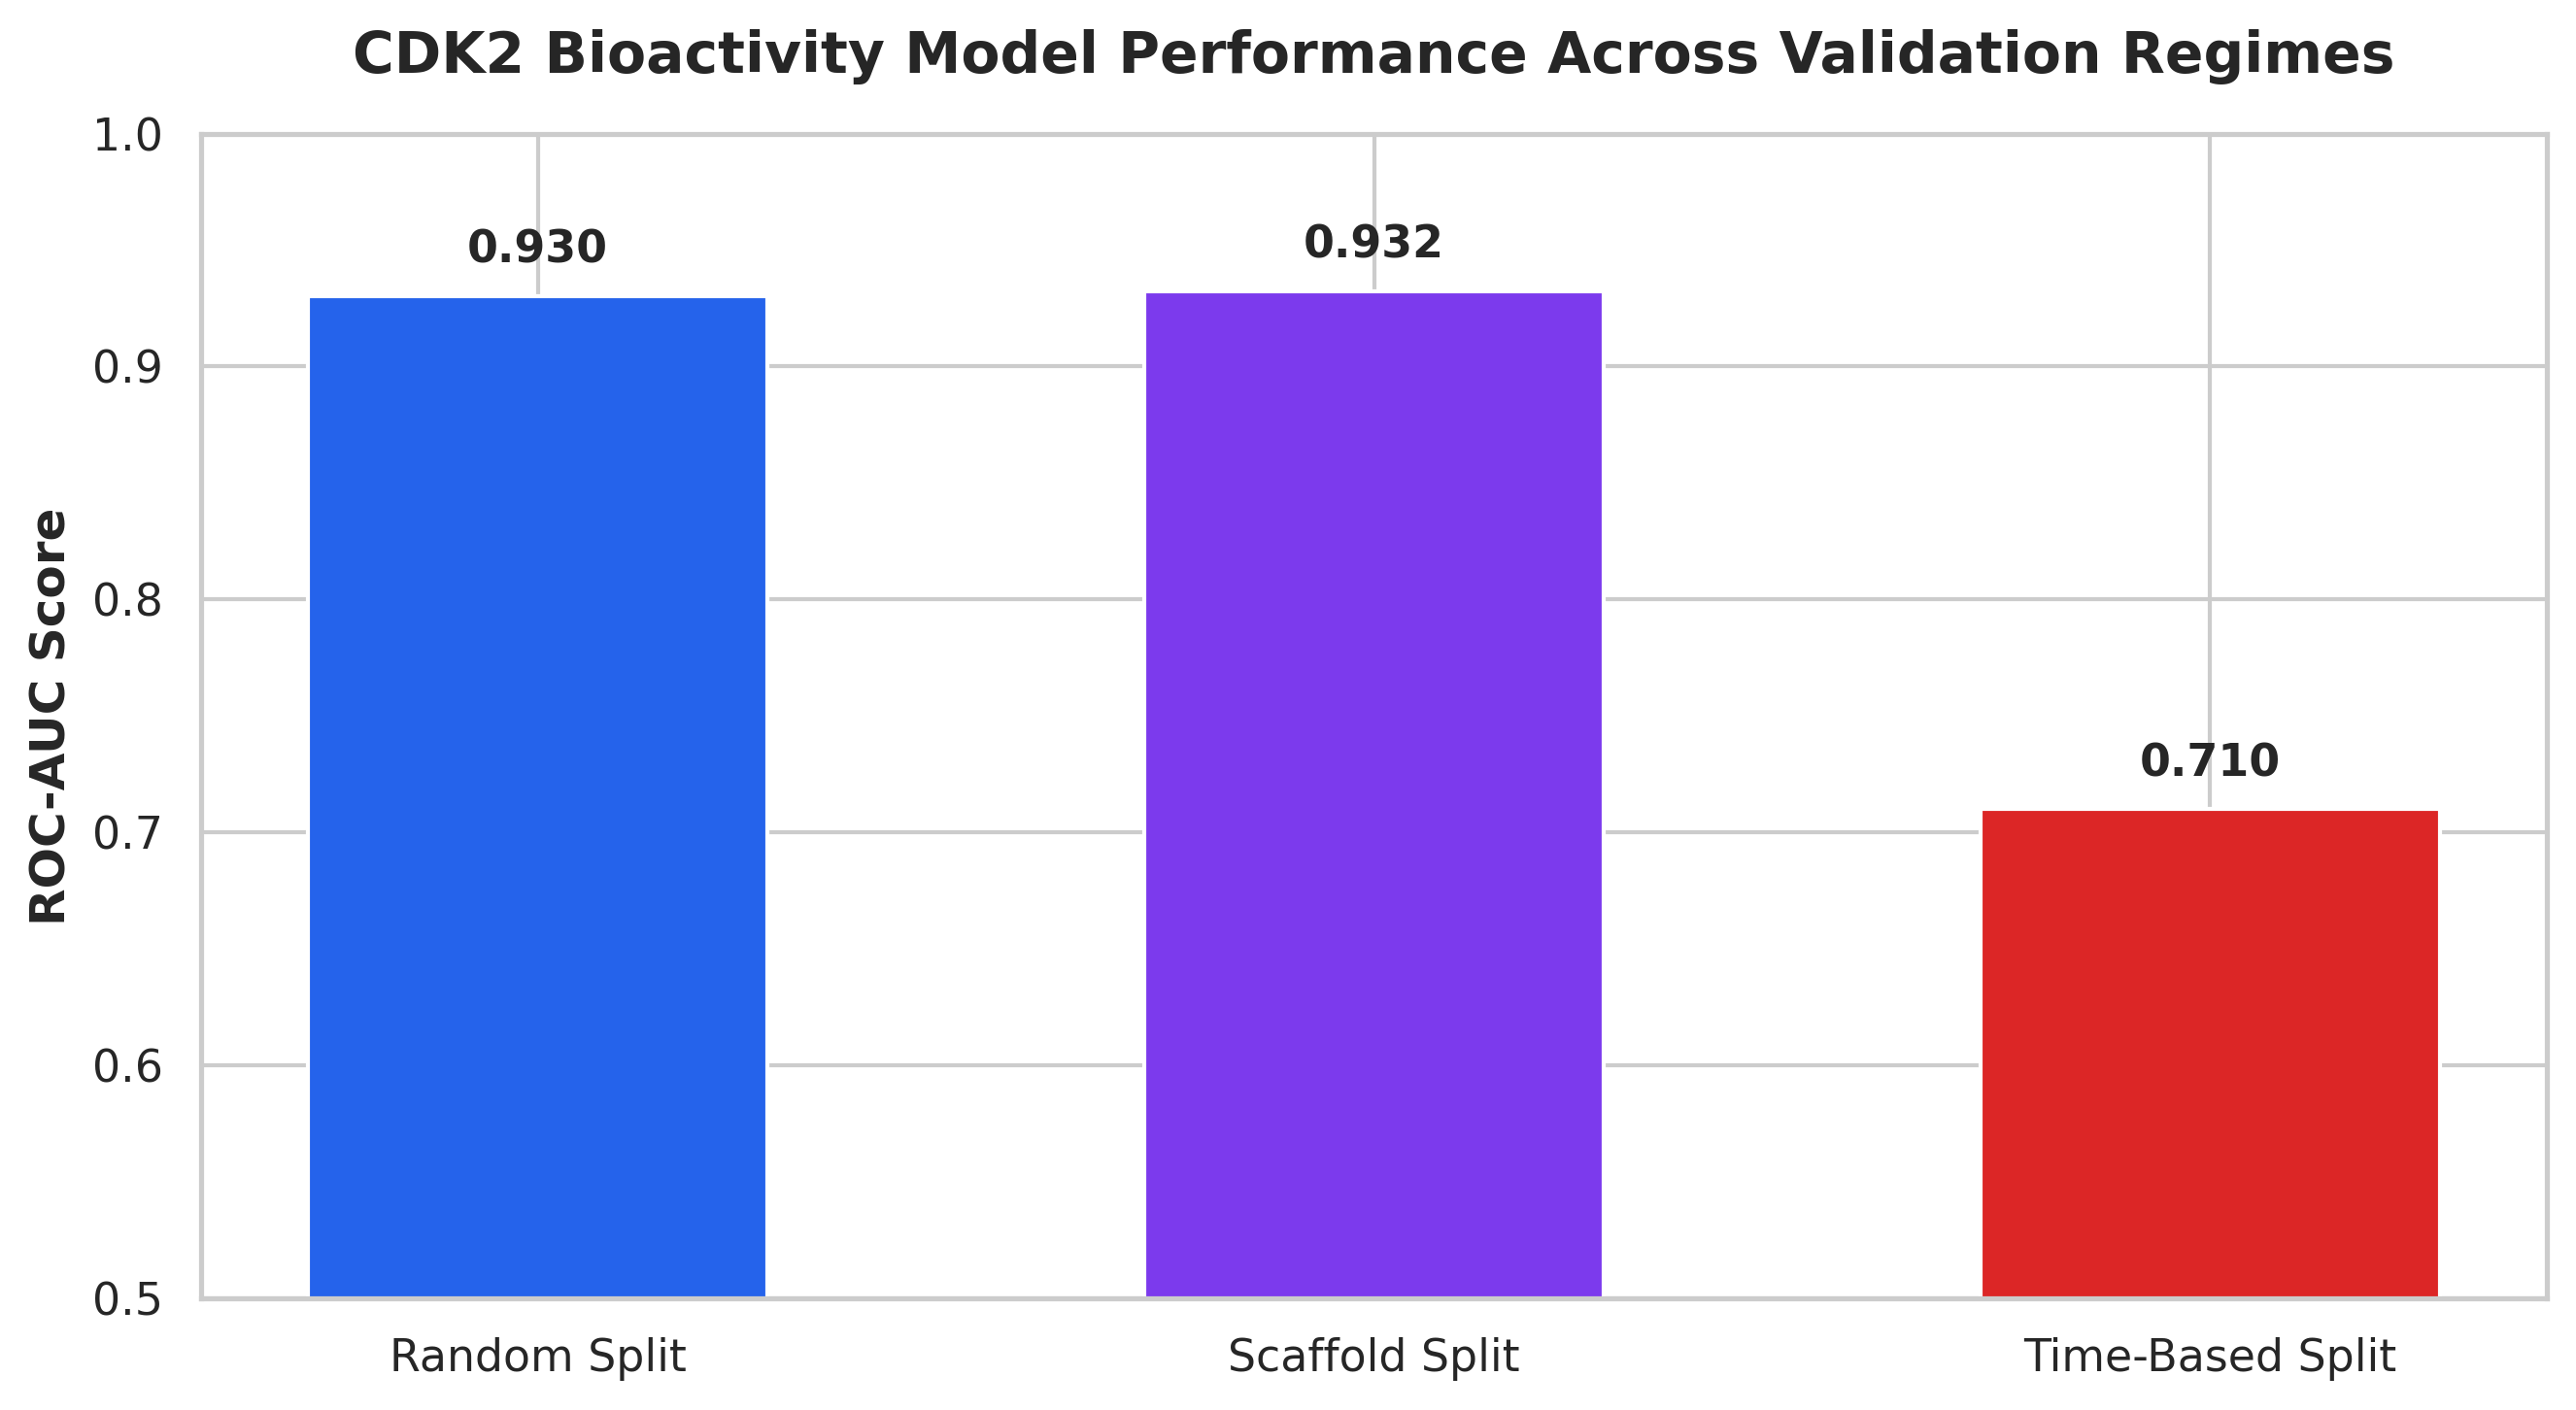


SUCCESS: Plot saved as 'cdk2_validation_comparison.png'!


In [3]:
# ==============================================================================
# DAYS 4-5: MODEL TRAINING & 3-WAY VALIDATION COMPARISON
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict

print("Loading featurized dataset...")
df = pd.read_csv("cdk2_featurized_dataset.csv")

# Separate features (X) and target (y)
feature_cols = [c for c in df.columns if c.startswith('Bit_') or c in ['MW', 'LogP', 'TPSA', 'HBD', 'HBA']]
X = df[feature_cols].values
y = df['active'].values

print(f"Total Features Loaded: {len(feature_cols)}")

# ------------------------------------------------------------------------------
# 1. SPLIT A: RANDOM SPLIT (80/20)
# ------------------------------------------------------------------------------
X_train_rnd, X_test_rnd, y_train_rnd, y_test_rnd = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# ------------------------------------------------------------------------------
# 2. SPLIT B: BEMIS-MURCKO SCAFFOLD SPLIT (80/20)
# ------------------------------------------------------------------------------
print("Generating Bemis-Murcko Scaffolds...")
scaffolds = defaultdict(list)
for idx, smiles in enumerate(df['canonical_smiles']):
    mol = Chem.MolFromSmiles(smiles)
    if mol:
        scaf = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
    else:
        scaf = ""
    scaffolds[scaf].append(idx)

# Sort scaffold sets by size descending
scaffold_sets = sorted(scaffolds.values(), key=lambda x: len(x), reverse=True)
train_idx_scaf, test_idx_scaf = [], []
target_test_count = int(len(df) * 0.20)

for scaf in scaffold_sets:
    if len(test_idx_scaf) + len(scaf) <= target_test_count or len(test_idx_scaf) == 0:
        test_idx_scaf.extend(scaf)
    else:
        train_idx_scaf.extend(scaf)

X_train_scaf, y_train_scaf = X[train_idx_scaf], y[train_idx_scaf]
X_test_scaf, y_test_scaf = X[test_idx_scaf], y[test_idx_scaf]

# ------------------------------------------------------------------------------
# 3. SPLIT C: PROSPECTIVE TIME-BASED SPLIT
# ------------------------------------------------------------------------------
# Determine cutoff year so ~80% is train and ~20% is test
cutoff_year = int(df['document_year'].quantile(0.80))
train_mask_time = df['document_year'] <= cutoff_year
test_mask_time = df['document_year'] > cutoff_year

X_train_time, y_train_time = X[train_mask_time], y[train_mask_time]
X_test_time, y_test_time = X[test_mask_time], y[test_mask_time]

print(f"Time Split Cutoff Year: {cutoff_year} (Train: {sum(train_mask_time)}, Test: {sum(test_mask_time)})")

# ------------------------------------------------------------------------------
# 4. TRAIN RANDOM FOREST MODELS & EVALUATE
# ------------------------------------------------------------------------------
def train_and_evaluate(X_tr, y_tr, X_te, y_te, name):
    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)

    y_pred = rf.predict(X_te)
    y_prob = rf.predict_proba(X_te)[:, 1]

    return {
        'Split Regime': name,
        'ROC-AUC': roc_auc_score(y_te, y_prob),
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'Test Samples': len(y_te)
    }

results = []
results.append(train_and_evaluate(X_train_rnd, y_train_rnd, X_test_rnd, y_test_rnd, "Random Split"))
results.append(train_and_evaluate(X_train_scaf, y_train_scaf, X_test_scaf, y_test_scaf, "Scaffold Split"))
results.append(train_and_evaluate(X_train_time, y_train_time, X_test_time, y_test_time, "Time-Based Split"))

results_df = pd.DataFrame(results)

print("\n" + "="*60)
print("       VALIDATION STRATEGY COMPARISON RESULTS")
print("="*60)
print(results_df.to_string(index=False))
print("="*60)

# ------------------------------------------------------------------------------
# 5. GENERATE PRESENTATION-READY COMPARISON PLOT
# ------------------------------------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)
sns.set_theme(style="whitegrid")

bars = plt.bar(results_df['Split Regime'], results_df['ROC-AUC'], color=['#2563eb', '#7c3aed', '#dc2626'], width=0.55)
plt.ylim(0.5, 1.0)
plt.ylabel("ROC-AUC Score", fontsize=12, fontweight='bold')
plt.title("CDK2 Bioactivity Model Performance Across Validation Regimes", fontsize=14, fontweight='bold', pad=15)

# Annotate metric values on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.3f}", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("cdk2_validation_comparison.png")
plt.show()

print("\nSUCCESS: Plot saved as 'cdk2_validation_comparison.png'!")

In [4]:
!pip install shap rdkit matplotlib

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Initialize TreeExplainer for Random Forest
explainer = shap.TreeExplainer(rf_model)

# 2. Compute SHAP values on the test set features (X_test)
shap_values = explainer.shap_values(X_test)

# For binary classification, index [1] represents the SHAP values for Class 1 (Active)
if isinstance(shap_values, list):
    shap_vals_active = shap_values[1]
else:
    shap_vals_active = shap_values[:, :, 1]

# 3. Plot global feature importance (Summary Beeswarm Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_active, X_test, max_display=15, show=False)
plt.title("Top 15 Features Driving CDK2 Bioactivity Predictions", fontsize=14)
plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=300)
plt.show()

NameError: name 'rf_model' is not defined

Training Random Forest model...
Model trained successfully!
Computing SHAP values...


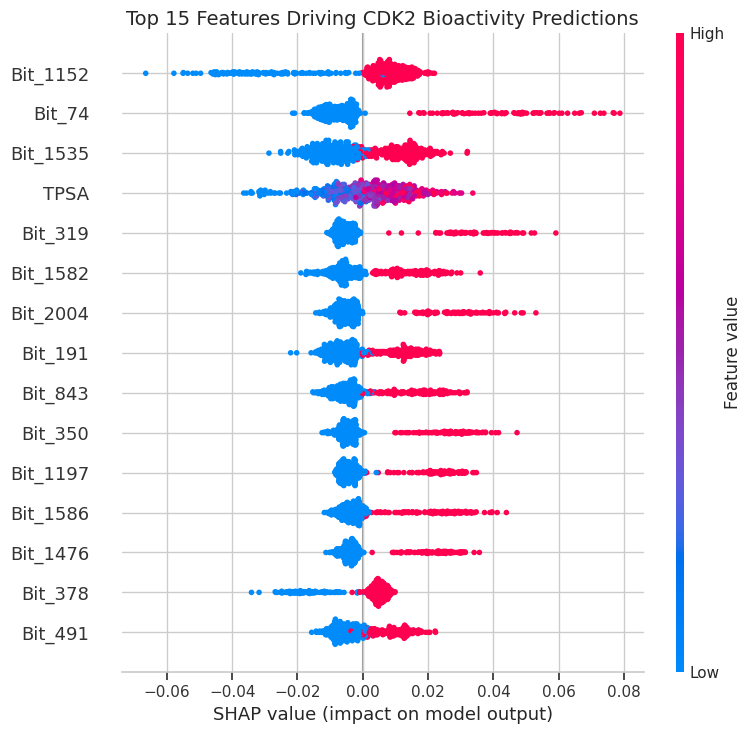

SUCCESS: SHAP plot generated and saved as 'shap_summary_plot.png'!


In [5]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Load featurized dataset saved from previous step
df_final = pd.read_csv("cdk2_featurized_dataset.csv")

# 2. Extract feature columns (5 Descriptors + 2048 Morgan Bits) and target label (active)
ignore_cols = ['molecule_chembl_id', 'canonical_smiles', 'document_year', 'active']
feature_cols = [col for col in df_final.columns if col not in ignore_cols]

X = df_final[feature_cols]
y = df_final['active']

# 3. Create Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Fit Random Forest Classifier
print("Training Random Forest model...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Model trained successfully!")

# 5. Compute SHAP Values
print("Computing SHAP values...")
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

# Handle output format differences across SHAP/scikit-learn versions
if isinstance(shap_values, list):
    shap_vals_active = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_active = shap_values[:, :, 1]
else:
    shap_vals_active = shap_values

# 6. Render and Save Summary Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_active, X_test, max_display=15, show=False)
plt.title("Top 15 Features Driving CDK2 Bioactivity Predictions", fontsize=14)
plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=300)
plt.show()
print("SUCCESS: SHAP plot generated and saved as 'shap_summary_plot.png'!")

Training set: 2263 compounds | Test set: 566 compounds
Generating Morgan Fingerprint vectors...


[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerator
[02:18:29] DEPRECATION WARNING: please use MorganGenerat

Computing maximum Tanimoto similarity to nearest training set neighbor...

APPLICABILITY DOMAIN (AD) ASSESSMENT COMPLETE
Total Test Compounds        : 566
Tanimoto Cutoff Threshold   : 0.6
In-Domain Predictions (Safe): 494 (87.3%)
Out-of-Domain (OOD) Flagged : 72 (12.7%)


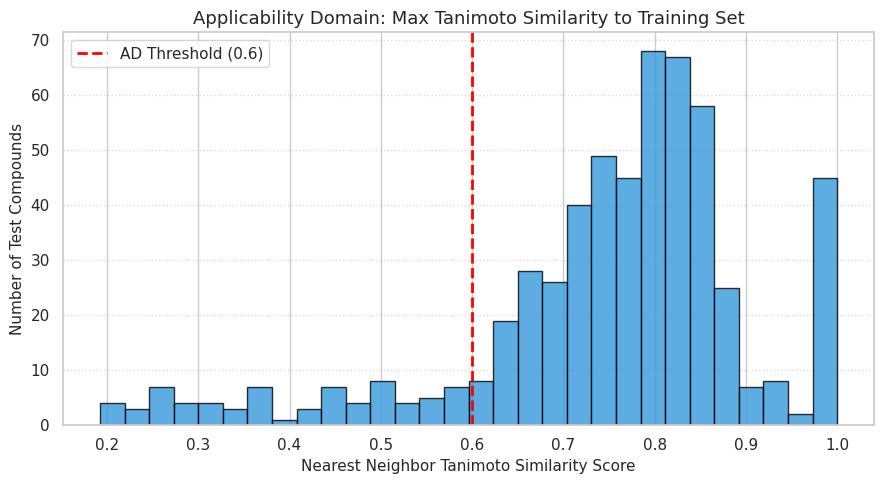

SUCCESS: Plot saved as 'applicability_domain_distribution.png'!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs
from rdkit.Chem import rdMolDescriptors
from sklearn.model_selection import train_test_split

# 1. Load featurized dataset
df = pd.read_csv("cdk2_featurized_dataset.csv")

# 2. Re-create Train / Test split (80/20 stratified split)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['active'])

print(f"Training set: {len(train_df)} compounds | Test set: {len(test_df)} compounds")

# 3. Generate RDKit fingerprint vectors for fast Tanimoto similarity calculations
print("Generating Morgan Fingerprint vectors...")
train_fps = [rdMolDescriptors.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), radius=2, nBits=2048)
             for s in train_df['canonical_smiles']]

test_fps = [rdMolDescriptors.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), radius=2, nBits=2048)
            for s in test_df['canonical_smiles']]

# 4. Compute Nearest-Neighbor Tanimoto Distance (Applicability Domain)
print("Computing maximum Tanimoto similarity to nearest training set neighbor...")
max_similarities = []
threshold = 0.60  # Industry standard similarity cutoff

for test_fp in test_fps:
    # BulkTanimotoSimilarity calculates pairwise Tanimoto scores against all training fingerprints
    sims = DataStructs.BulkTanimotoSimilarity(test_fp, train_fps)
    max_similarities.append(max(sims))

max_similarities = np.array(max_similarities)
in_domain_flags = (max_similarities >= threshold).astype(int)

# 5. Print Assessment Summary
in_domain_count = sum(in_domain_flags)
ood_count = len(in_domain_flags) - in_domain_count

print("\n" + "="*50)
print("APPLICABILITY DOMAIN (AD) ASSESSMENT COMPLETE")
print("="*50)
print(f"Total Test Compounds        : {len(test_df)}")
print(f"Tanimoto Cutoff Threshold   : {threshold}")
print(f"In-Domain Predictions (Safe): {in_domain_count} ({in_domain_count/len(test_df)*100:.1f}%)")
print(f"Out-of-Domain (OOD) Flagged : {ood_count} ({ood_count/len(test_df)*100:.1f}%)")
print("="*50)

# 6. Plot and Save Tanimoto Similarity Distribution
plt.figure(figsize=(9, 5))
plt.hist(max_similarities, bins=30, color='#3498db', edgecolor='black', alpha=0.8)
plt.axvline(x=threshold, color='red', linestyle='--', linewidth=2, label=f'AD Threshold ({threshold})')
plt.title("Applicability Domain: Max Tanimoto Similarity to Training Set", fontsize=13)
plt.xlabel("Nearest Neighbor Tanimoto Similarity Score", fontsize=11)
plt.ylabel("Number of Test Compounds", fontsize=11)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.savefig("applicability_domain_distribution.png", dpi=300)
plt.show()
print("SUCCESS: Plot saved as 'applicability_domain_distribution.png'!")